# 01: Coverage

*How completely does each knowledge graph represent the biomedical entities and relations relevant to drug repurposing?*

| Sub-metric | Definition | Quantification | Scoring |
|---|---|---|---|
| **Entity coverage** | Share of the reference entities of a type that the graph holds | \|KG ∩ Ref\| / \|Ref\|, per entity type | direct, 0-1 |
| **Relation coverage** | Share of the reference (head, tail) pairs of a relation that the graph holds | \|KG pairs ∩ Ref pairs\| / \|Ref pairs\|, per relation | direct, 0-1 |

The dimension score is the equal-weighted mean of the two.

**Scored.** Three entity types (Drug, Disease, Gene/Protein) and four relations (drug→gene, disease→gene, disease→disease, drug→disease).

**Reported, not scored.** Pathway entities and the two pathway relations, because the six graphs do not share a pathway vocabulary; disease coverage by stratum (all / rare / with an approved indication / without). A relation that cannot be asked of a graph is reported as N/A with its reason, not scored as zero.

Reference sets are task-derived and independent of the graphs being scored: approved drugs (ChEMBL, via Open Targets 26.06), all diseases (MONDO v2026-08-04), the targets of those approved drugs (Ensembl), and the Reactome pathways containing those targets.

**Inputs:** `config/kgs.yaml` · `config/params.yaml` · `data/reference_sets/` · `data/crosswalks/`

**Outputs:** `results/{figures,tables}/01_coverage/` · `results/checkpoints/01_coverage.pkl`

Design notes and justifications: [`README.md`](README.md)

## Set-up

KGs load from the paths in `config/kgs.yaml`; reference sets from `data/reference_sets/`, built by `tools/build_reference_sets.py` from Open Targets 26.06 and MONDO v2026-08-04. Coverage is computed exactly over the full sets, with no sampling.

In [73]:
# Pick up edits to src/ without restarting the kernel. Without this, editing a
# module after it has been imported leaves the kernel holding the old version,
# which surfaces as a confusing ImportError for a name that is plainly on disk.
try:
    get_ipython().run_line_magic('load_ext', 'autoreload')
    get_ipython().run_line_magic('autoreload', '2')
except Exception:
    pass                      # not running under IPython (headless runner, plain python)

import gc
import random
import sys
import warnings
from pathlib import Path

warnings.filterwarnings('ignore')

# Locate the repo root from any depth, then make the package importable.
# (`pip install -e .` also works and makes this block a no-op.)
_root = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
             if (p / 'config' / 'kgs.yaml').exists())
if str(_root / 'src') not in sys.path:
    sys.path.insert(0, str(_root / 'src'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from biokgsuite.io import Outputs, assert_full_panel, find_config, load_config, require
from biokgsuite.io.loading import load_kg
from biokgsuite.io.resolve import IdResolver
from biokgsuite.stats.coverage import (
    RelationSpec, entity_coverage, gap_decomposition, load_reference_sets,
    pathway_diagnostic, reactome_pathway_names, relation_coverage,
    schema_coverage, unmapped_types)
from biokgsuite.viz.primitives import coverage_heatmap
from biokgsuite.viz.style import setup_style

setup_style()

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [74]:
# Parameters are read with require(), never params.get(key, default): a silent
# default lets a run use a value config/params.yaml never mentions.
config = load_config(find_config(_root))
params = config['analysis_params']
BASE   = config['_base_dir']
REF    = BASE / 'data' / 'reference_sets'

# Every figure, table and checkpoint goes through `out`, so results land in
# results/{figures,tables}/01_coverage/ and
# results/checkpoints/01_coverage.pkl.
out = Outputs('01_coverage', BASE)

# A run that scores fewer graphs than config/kgs.yaml declares is a
# different experiment, not a smaller one, so it has to be asked for.
ALLOW_PARTIAL_PANEL = False


BKG_KGS=primekg,hetionet,biokg: TRIAL RUN on 3 of 6 graphs; checkpoints will record the reduced panel


### Loading

In [75]:
kgs = {}
for name in config['knowledge_graphs']:
    try:
        kg, nodes = load_kg(name, config)
        kgs[name] = {'kg': kg, 'nodes': nodes, 'type_counts': nodes['type'].value_counts()}
        print(f'{name:12s}: {len(kg):>12,} edges  {len(nodes):>8,} nodes  '
              f'{kg["relation"].nunique():>4} relation types')
    except FileNotFoundError:
        print(f'{name:12s}: [NOT FOUND]')
    except Exception as e:
        print(f'{name:12s}: [ERROR] {e}')

KG_NAMES        = list(kgs)
ENTITY_TYPE_MAP = {n: config['knowledge_graphs'][n].get('entity_types', {}) for n in KG_NAMES}
PATHWAY_KGS     = {n for n in KG_NAMES
                   if config['knowledge_graphs'][n].get('pathway_ontology') == 'reactome'}
# Refuse to score a panel that is missing graphs.
#
# The broad `except` above keeps one unreadable graph from taking down the run,
# but the cost is that a run finding two of six completes, prints a dimension
# score and writes a checkpoint indistinguishable from a full one. Scores that
# intersect or normalise across the panel then differ from what a full run would
# give, silently. Set ALLOW_PARTIAL_PANEL in the config cell to score a subset
# deliberately; the reduced panel is recorded in the checkpoint either way.
PANEL = assert_full_panel(KG_NAMES, config,
                          allow_partial=ALLOW_PARTIAL_PANEL,
                          notebook='01_coverage')


primekg     :    8,100,498 edges   129,375 nodes    30 relation types
hetionet    :    2,250,197 edges    47,031 nodes    24 relation types
biokg       :    2,067,998 edges   105,524 nodes    17 relation types
01_coverage: trial subset complete, 3 of 6 declared graphs loaded (BKG_KGS); not a full-panel run


### Schema coverage

Before measuring anything, check how much of each graph's own schema the config actually reads. An unmapped node type is silently excluded from every metric, which understates that graph for a reason that has nothing to do with its quality. Unmapped types are listed here and either mapped or dismissed explicitly.

In [76]:
# Did we read the whole graph? Every metric below is computed over nodes whose
# KG type label maps to a canonical type, so a label config/kgs.yaml does not
# mention is invisible: never counted and never checked. That is a gap in the
# config rather than a finding about the graph, and it is the one failure that
# makes a cross-graph comparison unfair rather than merely incomplete. Types
# declared but not scored (Symptom, Phenotype, Complex, ...) count as read;
# what remains unmapped here is dismissed, with its reason, in Methods.
schema = schema_coverage(kgs, ENTITY_TYPE_MAP)
out.table(schema, 'schema_coverage')
display(schema.set_index('KG'))

_unmapped = unmapped_types(kgs, ENTITY_TYPE_MAP)
if len(_unmapped):
    print('Node types present in a graph but not mapped in config/kgs.yaml.')
    print('Each must be mapped, or dismissed on the record in Methods.')
    display(_unmapped.set_index(['KG', 'Unmapped type']))
    out.table(_unmapped, 'unmapped_types')
else:
    print('Every node type in every graph maps to a canonical type.')

,Node types,Mapped,Unmapped,Nodes,Nodes mapped (%),Unmapped types
KG,,,,,,
primekg,10,10,0,129375,100.0,-
hetionet,11,11,0,47031,100.0,-
biokg,6,6,0,105524,100.0,-


Every node type in every graph maps to a canonical type.


In [77]:
# Scoring scope. Pathways are computed and reported everywhere below but never
# enter the score: the six graphs key pathways by Reactome, KEGG, SMPDB and
# PathwayCommons accessions, so matching on identifier asks which source a
# graph ingested rather than what biology it holds. The pathway diagnostic near
# the end makes that case with numbers; data/REFERENCE_SETS.md has the argument.
SCORED_ENTITY_TYPES = ['Drug', 'Disease', 'Gene/Protein']
SCORED_RELATIONS    = ['drug_gene', 'disease_gene', 'disease_disease', 'drug_disease']
REPORTED_NOT_SCORED = {'Pathway', 'drug_pathway', 'disease_pathway'}

def is_evaluable(kg_name, entity_type):
    """Pathway coverage is only meaningful for a KG that speaks Reactome."""
    return not (entity_type == 'Pathway' and kg_name not in PATHWAY_KGS)

### Reference sets

Loaded once from `data/reference_sets/` and shared across all six graphs, so no KG is matched against a standard tailored to it. Built by `tools/build_reference_sets.py`; see `data/REFERENCE_SETS.md` for the rule behind each set and `data/PROVENANCE.md` for the dated, checksummed record of every input file.

In [78]:
REFS = load_reference_sets(REF)
display(REFS.summary())
out.table(REFS.summary(), 'reference_sets')

,Kind,Set,N
0,entity,Drug,5485
1,entity,Disease,31147
2,entity,Gene/Protein,1076
3,entity,Pathway,1386
4,disease stratum,rare,15656
5,disease stratum,drugged,946
6,disease stratum,undrugged,30201
7,relation,drug_gene,7922
8,relation,drug_pathway,22019
9,relation,disease_gene,18841


PosixPath('/Users/shil6661/Desktop/biokgsuite-bib/results/tables/01_coverage/reference_sets.csv')

## 1. Entity coverage

$$\text{Entity Coverage}_t = \frac{|\text{KG}_t \cap \text{Ref}_t|}{|\text{Ref}_t|}$$

for entity type $t$. Every KG identifier is resolved into the reference namespace before matching: drugs to ChEMBL, diseases to MONDO, genes to Ensembl, pathways to Reactome. Resolution dispatches on the identifier's own namespace rather than on which KG supplied it, so all six graphs are given the same crosswalks. Pathway coverage is computed only for KGs declaring `pathway_ontology: reactome`, and is reported rather than scored.

In [79]:
# One resolution pipeline for all six graphs. IdResolver dispatches on the
# namespace of the identifier rather than on which KG supplied it, so no graph
# receives more ID-rescuing effort than another. The per-KG bridges this
# replaced meant coverage partly measured how much work we had done on each.
_XW = BASE / 'data' / 'crosswalks'
if not _XW.exists():
    raise FileNotFoundError(f'{_XW} missing. Run:  python tools/build_crosswalks.py')
resolver = IdResolver(_XW)

entity_sets, _rows = {}, []
for kg_name, data in kgs.items():
    sets = {}
    for canonical, kg_labels in ENTITY_TYPE_MAP[kg_name].items():
        if canonical not in resolver.RESOLVERS:
            continue
        # One canonical type may be spelled by several KG labels; they are
        # pooled before resolution so the union is de-duplicated once.
        edges = data['kg']
        raw = set(pd.concat([edges.loc[edges['x_type'].isin(kg_labels), 'x_id'],
                             edges.loc[edges['y_type'].isin(kg_labels), 'y_id']],
                            ignore_index=True).dropna().astype(str).str.strip()) - {''}
        sets[canonical], stat = resolver.resolve(canonical, raw)
        _rows.append(stat.as_row(KG=kg_name, Entity=canonical))
    entity_sets[kg_name] = sets

resolvability = (pd.DataFrame(_rows)[['KG', 'Entity', 'raw', 'resolved', 'resolvability',
                                      'canonical_ids', 'top_unresolved']]
                 .sort_values(['Entity', 'KG']).reset_index(drop=True))
print("Resolvability: the fraction of each KG's own IDs that reach the reference")
print('namespace. Coverage is computed on the resolved subset, so a low value here')
print('caps what that graph can attain for reasons of notation, not content.')
display(resolvability)
out.table(resolvability, 'resolvability')

  unichem_drugbank_chembl.tsv missing — DrugBank ids resolve only through Open Targets cross-references (about half of approved drugs). Run tools/fetch_unichem.sh
  unichem PubChem->ChEMBL: 2,832,793 CIDs
IdResolver: disease 127,318 ids -> MONDO | drug 31,562 -> ChEMBL | gene 315,505 -> Ensembl
Resolvability: the fraction of each KG's own IDs that reach the reference
namespace. Coverage is computed on the resolved subset, so a low value here
caps what that graph can attain for reasons of notation, not content.


,KG,Entity,raw,resolved,resolvability,canonical_ids,top_unresolved
0,biokg,Disease,9490,8052,0.8485,6870,"MeSH:1,420; MIM:18"
1,hetionet,Disease,136,136,1.0000,136,
2,primekg,Disease,17080,16152,0.9457,20817,integer:910; grouped:18
3,biokg,Drug,8805,5889,0.6688,8914,"DrugBank:2,916"
4,hetionet,Drug,1538,1451,0.9434,2899,DrugBank:87
5,primekg,Drug,7957,5400,0.6786,8305,"DrugBank:2,557"
6,biokg,Gene/Protein,59204,16483,0.2784,16575,"UniProt:42,721"
7,hetionet,Gene/Protein,19145,19028,0.9939,19028,integer:117
8,primekg,Gene/Protein,27610,27272,0.9878,27273,integer:338
9,biokg,Pathway,14779,1956,0.1323,1956,"Reactome:9,031; bare:3,792"


PosixPath('/Users/shil6661/Desktop/biokgsuite-bib/results/tables/01_coverage/resolvability.csv')

In [80]:
# A whole entity type failing to resolve is a MISSING CROSSWALK, not a finding
# about the graph, and it is the failure most easily mistaken for a result: the
# KG looks empty when in truth none of its identifiers could be read. Pathway is
# exempt, since a non-Reactome vocabulary is expected and separately reported.
RESOLVABILITY_FLOOR = require(params, 'resolvability_floor')

_susp = resolvability[(resolvability['resolvability'] < RESOLVABILITY_FLOOR)
                      & (resolvability['Entity'].isin(SCORED_ENTITY_TYPES))]
if len(_susp):
    print('!' * 72)
    print('UNRESOLVABLE ENTITY TYPES — the coverage below is INVALID for these')
    for _, r in _susp.iterrows():
        print(f"  {r['KG']:12s} {r['Entity']:14s} {r['resolved']:,}/{r['raw']:,} "
              f"resolved   unresolved: {r['top_unresolved'] or 'n/a'}")
    print('  PubChem CIDs need tools/fetch_unichem.sh; any other namespace needs')
    print('  a loader in src/biokgsuite/io/resolve.py. Do not report these.')
    print('!' * 72)
else:
    print(f'All scored entity types resolve above {RESOLVABILITY_FLOOR:.0%} in every KG.')

All scored entity types resolve above 5% in every KG.


### Coverage computation

Entity sets are extracted per KG, normalised to canonical IDs, and intersected with the gold standard; per-entity membership CSVs are exported.

In [81]:
entity_summary, membership = entity_coverage(entity_sets, REFS, is_evaluable)
display(entity_summary.set_index(['KG', 'Entity Type']))
out.table(entity_summary, 'entity_coverage')

KG Entities  Gold Standard  Overlap  Coverage (%)
KG       Entity Type                                                    
primekg  Drug                 8305           5485   3417.0         62.30
         Disease             20817          31147  19878.0         63.82
         Gene/Protein        27273           1076   1074.0         99.81
         Pathway              2492           1386   1205.0         86.94
hetionet Drug                 2899           5485   1960.0         35.73
         Disease               136          31147    132.0          0.42
         Gene/Protein        19028           1076   1073.0         99.72
         Pathway                 0           1386      NaN           NaN
biokg    Drug                 8914           5485   3454.0         62.97
         Disease              6870          31147   6617.0         21.24
         Gene/Protein        16575           1076   1076.0        100.00
         Pathway              1956           1386   1134.0         81.82

PosixPath('/Users/shil6661/Desktop/biokgsuite-bib/results/tables/01_coverage/entity_coverage.csv')

### Diagnostic entity coverage gaps

Curator aids (not scored): cross-KG overlap, how many KGs cover each gold entity, and a sample of missing IDs per KG, to separate ID-mapping failures from genuine absence.

In [82]:
# How many KGs cover each reference entity, and a sample of what each one misses.
# Both separate an ID-mapping failure from a genuine absence; neither is scored.
random.seed(require(params, 'random_seed'))
N_SAMPLE_MISSING = 10

overlap_rows, missing_rows = [], []
for etype, ref in REFS.entities.items():
    per_kg = membership.get(etype, {})
    if not per_kg:
        continue
    n_covering = pd.Series(
        [sum(gid in per_kg[kg]['matched'] for kg in per_kg) for gid in ref])
    # Reindexed over every level, so a level no reference entity reaches shows
    # as 0 rather than dropping out and leaving a gap in the table.
    counts = n_covering.value_counts().reindex(range(len(per_kg) + 1), fill_value=0)
    for n, count in counts.items():
        overlap_rows.append({'Entity Type': etype, 'Covered by': f'{n}/{len(per_kg)} KGs',
                             'Count': int(count),
                             '% of Reference': round(100 * count / len(ref), 1)})
    for kg, res in per_kg.items():
        unmatched = sorted(res['unmatched'])
        for sid in random.sample(unmatched, min(N_SAMPLE_MISSING, len(unmatched))):
            missing_rows.append({'KG': kg, 'Entity Type': etype, 'Missing Reference ID': sid})

overlap_df, missing_examples = pd.DataFrame(overlap_rows), pd.DataFrame(missing_rows)
out.table(overlap_df, 'entity_overlap_across_kgs')
out.table(missing_examples, 'entity_missing_examples')
display(overlap_df)

,Entity Type,Covered by,Count,% of Reference
0,Drug,0/3 KGs,1965,35.8
1,Drug,1/3 KGs,160,2.9
2,Drug,2/3 KGs,1409,25.7
3,Drug,3/3 KGs,1951,35.6
4,Disease,0/3 KGs,11196,35.9
5,Disease,1/3 KGs,13362,42.9
6,Disease,2/3 KGs,6502,20.9
7,Disease,3/3 KGs,87,0.3
8,Gene/Protein,0/3 KGs,0,0.0
9,Gene/Protein,1/3 KGs,2,0.2


### Visualisation

  saved entity_coverage.pdf and .png (600 dpi)


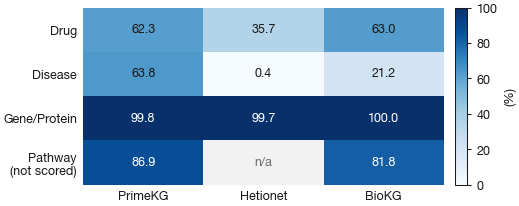

In [83]:
pivot = (entity_summary.pivot(index='Entity Type', columns='KG', values='Coverage (%)')
         .reindex(index=[e for e in REFS.entities if e in set(entity_summary['Entity Type'])],
                  columns=KG_NAMES))
fig = coverage_heatmap(pivot, 'Entity coverage against task-derived reference sets',
                       subtitle='share of the reference entities each graph contains',
                       not_scored=REPORTED_NOT_SCORED)
out.figure(fig, 'entity_coverage')
plt.show()

## 2. Relation coverage

$$\text{Relation Coverage}_r = \frac{|\text{KG pairs}_r \cap \text{Ref pairs}_r|}{|\text{Ref pairs}_r|}$$

Six relations, chosen because they are the edge types the grounding dossier actually reads (`src/biokgsuite/grounding/dossiers.py`). Four are scored; the two pathway relations are reported only.

Edges are selected **by endpoint entity type, not by relation name**. That matches how the dossier gathers neighbours, and it avoids the asymmetry where a graph reusing one predicate across two relation classes is counted twice. Both endpoints must resolve into the reference namespace for a KG pair to qualify.

Reference pairs come from Open Targets 26.06 and MONDO v2026-08-04. None is DrugBank-derived, so none is circular with the graphs being scored; see `data/REFERENCE_SETS.md`.

In [84]:
# The six edge types the grounding dossier reads, named by their endpoints.
REL_SPECS = [
    RelationSpec('drug_gene',       'Drug',    'Gene/Protein'),
    RelationSpec('drug_pathway',    'Drug',    'Pathway'),
    RelationSpec('disease_gene',    'Disease', 'Gene/Protein'),
    RelationSpec('disease_pathway', 'Disease', 'Pathway'),
    RelationSpec('disease_disease', 'Disease', 'Disease', symmetric=True),
    RelationSpec('drug_disease',    'Drug',    'Disease'),
]

RELATION_RESULTS, relation_summary = relation_coverage(
    kgs, ENTITY_TYPE_MAP, REL_SPECS, REFS, resolver, is_evaluable)
display(relation_summary)
out.table(relation_summary, 'relation_coverage')

,KG,Relation,KG pairs,Overlap,Gold,Coverage (%),Note
0,primekg,drug_gene,39028,3631.0,7922,45.83,
1,hetionet,drug_gene,100169,3422.0,7922,43.20,
2,biokg,drug_gene,41234,4249.0,7922,53.64,
3,primekg,drug_pathway,0,0.0,22019,0.00,
4,hetionet,drug_pathway,0,NaN,22019,NaN,not evaluable (endpoint type not scored for th...
5,biokg,drug_pathway,0,0.0,22019,0.00,
6,primekg,disease_gene,229206,9904.0,18841,52.57,
7,hetionet,disease_gene,27635,420.0,18841,2.23,
8,biokg,disease_gene,29343,5284.0,18841,28.05,
9,primekg,disease_pathway,0,0.0,72701,0.00,


PosixPath('/Users/shil6661/Desktop/biokgsuite-bib/results/tables/01_coverage/relation_coverage.csv')

### Visualisation

  saved relation_coverage.pdf and .png (600 dpi)


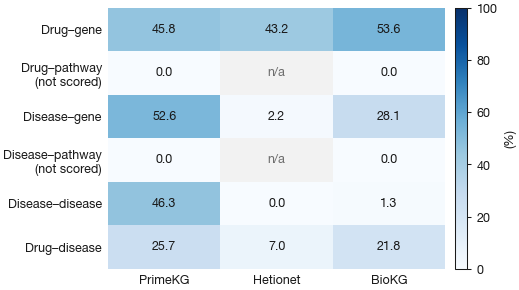

In [85]:
pivot_rel = (pd.DataFrame([{'KG': kg, 'Relation': rel, 'Coverage (%)': res['coverage_pct']}
                           for rel, per_kg in RELATION_RESULTS.items()
                           for kg, res in per_kg.items()])
             .pivot(index='Relation', columns='KG', values='Coverage (%)')
             .reindex(index=[s.name for s in REL_SPECS], columns=KG_NAMES))
fig = coverage_heatmap(pivot_rel, 'Relation coverage against task-derived reference sets',
                       subtitle='share of the reference pairs each graph links',
                       not_scored=REPORTED_NOT_SCORED)
out.figure(fig, 'relation_coverage')
plt.show()

### Diagnostic relation coverage gaps

Separates missing pairs into entity-absent, relation-not-curated, or ID-mapping failure, per relation type.

In [86]:
relation_gaps = gap_decomposition(RELATION_RESULTS, entity_sets, REL_SPECS)
display(relation_gaps)
out.table(relation_gaps, 'relation_gap_decomposition')

,KG,Relation,Missing,Both present (edge absent),One entity absent,Both entities absent
0,primekg,drug_gene,4291,2794,1495,2
1,hetionet,drug_gene,4500,1315,3182,3
2,biokg,drug_gene,3673,2161,1512,0
3,primekg,drug_pathway,22019,13997,7234,788
4,biokg,drug_pathway,22019,13016,7975,1028
5,primekg,disease_gene,8937,7235,1699,3
6,hetionet,disease_gene,18421,456,17736,229
7,biokg,disease_gene,13557,4639,8648,270
8,primekg,disease_pathway,72701,56528,15199,974
9,biokg,disease_pathway,72701,32174,34068,6459


PosixPath('/Users/shil6661/Desktop/biokgsuite-bib/results/tables/01_coverage/relation_gap_decomposition.csv')

## Pathways: reported, not scored

The score covers three entity types and four relations. Pathway entities, drug→pathway and disease→pathway are computed identically to everything else and stored in the checkpoint, but held out of the mean.

The cell below is the justification, not a footnote to it. It reports what pathway coverage *would* have been alongside the statistic that explains it: the share of each graph's pathway nodes that carry a Reactome accession at all. Where those two columns move together, the metric is reading vocabulary rather than biology.

In [87]:
PATHWAY_DIAGNOSTIC = pathway_diagnostic(
    kgs, ENTITY_TYPE_MAP, PATHWAY_KGS, membership, RELATION_RESULTS,
    reactome_pathway_names(REF))
display(PATHWAY_DIAGNOSTIC.set_index('KG'))
out.table(PATHWAY_DIAGNOSTIC, 'pathway_diagnostic')
print('A high name-match beside a zero or N/A coverage is the vocabulary artefact')
print('that keeps these three columns out of the dimension score. N/A means the KG')
print('declares no Reactome vocabulary, so the question cannot be asked of it.')

,Reactome declared,Pathway nodes,R-HSA accessions,% R-HSA,Distinct names,Name matches,% name match,Entity (%),drug→pathway (%),disease→pathway (%)
KG,,,,,,,,,,
primekg,True,2516,2516,100.0,2498,1890,75.7,86.94,0.0,0.0
hetionet,False,1822,0,0.0,1808,873,48.3,NaN,NaN,NaN
biokg,True,14779,1974,13.4,6103,1737,28.5,81.82,0.0,0.0


A high name-match beside a zero or N/A coverage is the vocabulary artefact
that keeps these three columns out of the dimension score. N/A means the KG
declares no Reactome vocabulary, so the question cannot be asked of it.


## Dimension score

$$\text{Coverage} = \tfrac{1}{2}\left(\text{Entity Coverage} + \text{Relation Coverage}\right)$$

Each sub-metric averages over the **scored types that are evaluable in every KG**, so the comparison is like for like.

| | scored | computed and stored, not scored |
|---|---|---|
| Entities | Drug, Disease, Gene/Protein | Pathway |
| Relations | drug→gene, disease→gene, disease→disease, drug→disease | drug→pathway, disease→pathway |

Pathways are excluded for vocabulary mismatch across the six graphs, not for irrelevance; see the diagnostic above. Everything held out is still written to the checkpoint, so the exclusion can be reversed or audited without a rerun.

In [88]:
def _ok(v):
    return v is not None and v == v          # not None, not NaN

def _scalar(res):
    """Drop the large ID sets; keep what downstream notebooks read."""
    ovl = res['overlap_n']
    return {'pct': res['coverage_pct'],
            'overlap': int(ovl) if _ok(ovl) else None,
            'gold': int(res['gold_n'])}

# Read back from the single `entity_coverage` computation above rather than
# recomputed from the raw sets. Two code paths producing the same number is how
# a displayed table and a reported score drift apart without anyone noticing.
# None marks "computed but not evaluable for this KG", as distinct from absent.
def _entity_cov(kg, etype):
    res = membership.get(etype, {}).get(kg)
    return None if res is None else round(res['overlap_n'] / res['gold_n'], 4)

entity_cov = {kg: {et: _entity_cov(kg, et) for et in sets if et in REFS.entities}
              for kg, sets in entity_sets.items()}

relation_cov = {kg: {rel: _scalar(per_kg[kg]) for rel, per_kg in RELATION_RESULTS.items()}
                for kg in KG_NAMES}

# Disease coverage split by stratum. A pooled number hides what the benchmark
# exists to show: whether the graphs are populated where repurposing is needed
# most, which is precisely where no approved drug exists.
disease_strata_cov = {
    kg: {'all': round(len(sets.get('Disease', set()) & REFS.entities['Disease'])
                      / len(REFS.entities['Disease']), 4),
         **{name: round(len(sets.get('Disease', set()) & ids) / len(ids), 4)
            for name, ids in REFS.strata.items()}}
    for kg, sets in entity_sets.items()}

# Scored types that every KG can be evaluated on, so the comparison is like for like.
SHARED_ENTITY_TYPES = sorted(
    set.intersection(*(set(entity_cov[kg]) for kg in KG_NAMES)) & set(SCORED_ENTITY_TYPES))
SHARED_RELATION_TYPES = sorted(
    rel for rel in SCORED_RELATIONS
    if all(_ok(relation_cov[kg][rel]['pct']) for kg in KG_NAMES))

print(f'Scored entity types, shared by every KG ({len(SHARED_ENTITY_TYPES)}): '
      f'{SHARED_ENTITY_TYPES}')
print(f'Scored relations,    shared by every KG ({len(SHARED_RELATION_TYPES)}): '
      f'{SHARED_RELATION_TYPES}')
_dropped = ([e for e in SCORED_ENTITY_TYPES if e not in SHARED_ENTITY_TYPES]
            + [r for r in SCORED_RELATIONS if r not in SHARED_RELATION_TYPES])
if _dropped:
    print(f'NOTE: scored in principle but not evaluable in every KG, so held '
          f'out of the mean: {_dropped}')

sub_scores = {}
for kg in KG_NAMES:
    # relation coverage is stored 0-100 and entity coverage 0-1; both enter the
    # mean on the 0-1 scale.
    rel_vals = [relation_cov[kg][r]['pct'] / 100 for r in SHARED_RELATION_TYPES]
    sub_scores[kg] = {
        'entity_coverage':   round(float(np.mean([entity_cov[kg][e]
                                                  for e in SHARED_ENTITY_TYPES])), 4),
        'relation_coverage': round(float(np.mean(rel_vals)), 4) if rel_vals else float('nan'),
        'disease_strata':    disease_strata_cov.get(kg, {})}

summary_scores = {kg: round(float(np.mean([sub_scores[kg]['entity_coverage'],
                                           sub_scores[kg]['relation_coverage']])), 4)
                  for kg in KG_NAMES}

scores = pd.DataFrame([
    {'KG': kg, 'coverage_score': summary_scores[kg],
     'entity_coverage': sub_scores[kg]['entity_coverage'],
     'relation_coverage': sub_scores[kg]['relation_coverage'],
     **{f'disease_{k}': v for k, v in disease_strata_cov[kg].items()}}
    for kg in KG_NAMES])
out.table(scores, 'dimension_scores')
display(scores.set_index('KG'))

Scored entity types, shared by every KG (3): ['Disease', 'Drug', 'Gene/Protein']
Scored relations,    shared by every KG (4): ['disease_disease', 'disease_gene', 'drug_disease', 'drug_gene']


,coverage_score,entity_coverage,relation_coverage,disease_all,disease_rare,disease_drugged,disease_undrugged
KG,,,,,,,
primekg,0.5896,0.7531,0.4260,0.6382,0.8708,0.9915,0.6271
hetionet,0.2920,0.4529,0.1311,0.0042,0.0030,0.0888,0.0016
biokg,0.4380,0.6140,0.2620,0.2124,0.3293,0.7241,0.1964


In [89]:
ckpt = {
    'summary_scores':        summary_scores,
    'sub_scores':            sub_scores,
    'entity_cov':            entity_cov,
    'relation_coverage':     relation_cov,
    'shared_entity_types':   SHARED_ENTITY_TYPES,
    'shared_relation_types': SHARED_RELATION_TYPES,
    # The scoring scope, recorded so downstream notebooks and the paper can
    # state what was and was not scored without re-deriving it.
    'scored_entity_types':   SCORED_ENTITY_TYPES,
    'scored_relations':      SCORED_RELATIONS,
    'reported_not_scored':   sorted(REPORTED_NOT_SCORED),
    'pathway_diagnostic':    PATHWAY_DIAGNOSTIC.set_index('KG').to_dict('index'),
    'kg_stats': {name: {'n_edges': int(len(d['kg'])), 'n_nodes': int(len(d['nodes'])),
                        'n_relations': int(d['kg']['relation'].nunique())}
                 for name, d in kgs.items()},
}

out.checkpoint(ckpt)
print(out.summary())

01_coverage: wrote 15 files
  results/checkpoints/01_coverage.pkl
  results/figures/01_coverage/entity_coverage.pdf
  results/figures/01_coverage/entity_coverage.png
  results/figures/01_coverage/relation_coverage.pdf
  results/figures/01_coverage/relation_coverage.png
  results/tables/01_coverage/dimension_scores.csv
  results/tables/01_coverage/entity_coverage.csv
  results/tables/01_coverage/entity_missing_examples.csv
  results/tables/01_coverage/entity_overlap_across_kgs.csv
  results/tables/01_coverage/pathway_diagnostic.csv
  results/tables/01_coverage/reference_sets.csv
  results/tables/01_coverage/relation_coverage.csv
  results/tables/01_coverage/relation_gap_decomposition.csv
  results/tables/01_coverage/resolvability.csv
  results/tables/01_coverage/schema_coverage.csv


In [90]:
# Free KG state before the next notebook, which loads the same graphs again.
# Without this both sets stay resident and the kernel is OOM-killed.
for _v in ('kgs', 'entity_sets', 'membership', 'RELATION_RESULTS', 'resolver'):
    globals().pop(_v, None)
print(f'Released KG state; {gc.collect():,} objects collected.')
print('\nCoverage: ' + '  '.join(f'{k} {v:.4f}' for k, v in summary_scores.items()))

Released KG state; 3,901 objects collected.

Coverage: primekg 0.5896  hetionet 0.2920  biokg 0.4380
